# Sparse wafer-map metrology, part 4: how many full maps, how many sites, and the plan
Part 3 settled what to trust and where to measure, with every choice made on training lots. Part 4
turns that into a measurement plan and asks what it costs:

1. **How many sites per wafer**: the fewest chosen sites that do no worse than the routine 9,
   decided on training lots.
2. **The deployment number**: the whole plan learned only from earlier lots, as a fab would have to,
   with its gap to leave-one-lot-out.
3. **Staleness**: a plan learned once from lots 1 to 3 and never updated.
4. **How many fully measured wafers it needs**, and whether they should come from one lot or many.
5. **The cost**, in sites measured and full maps, and the measurement plan in one paragraph.

The same rule as part 3: every choice is made on training lots (by hiding one training lot at a
time), and the held-out lot is used once, to score. All 10 lots were looked at in parts 1 to 3, so
training only on earlier lots (section 5) is the number closest to real use.

**To run:** in Colab, Runtime → Run all. The data loads from this repository's `data/` folder (or
straight from GitHub). Runs in about 3 minutes.

Data: Langer et al., BOSCH plasma-etching dataset, Zenodo 2025, doi:10.5281/zenodo.17122442 (CC BY 4.0).

## 0. Setup: data, the bad-reading screen and the random layouts
Copied unchanged from notebook 03 so that this notebook runs on its own.

In [1]:
# Tools: numpy for arrays, pandas for tables, matplotlib for plots
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Where the data files are: the repository's data/ folder, or GitHub itself (e.g. in Colab)
DATA_URL = 'https://raw.githubusercontent.com/arifulRPI/sparse-wafer-metrology/main/data/'
def data_path(name):
    for folder in ['data', '../data', '.']:
        if os.path.exists(os.path.join(folder, name)):
            return os.path.join(folder, name)
    return DATA_URL + name

# Where figures go: the repository's figures/ folder if we're inside it, else the current folder
FIG_DIR = next((d for d in ['figures', '../figures'] if os.path.isdir(d)), '.')

full = pd.read_csv(data_path('Si_Oxide_etch_89_points.csv'))  # 89 sites per wafer (Feb 2025, KLA Tencor P-17)
rout = pd.read_csv(data_path('Si_Oxide_etch_9_points.csv'))   # 9 routine sites per wafer (etch day, Veeco Dektak 8)
TARGET = 'stepheight'      # main target; silicon etch depth is repeated in section 8

In [2]:
# The wafer x site tables: one row per wafer, one column per site
full['site'] = list(zip(full.X // 1000, full.Y // 1000))          # site = (x, y) in mm
sites = sorted(full.site.unique(), key=lambda s: (-s[1], s[0]))    # fixed order: top row first
wafers = full[['experiment_key', 'lot_number', 'wafer_number']].drop_duplicates()
wafers = wafers.sort_values(['lot_number', 'wafer_number']).reset_index(drop=True)
def table(column):
    """88 x 89 array of one measured quantity (µm), rows in lot/wafer order."""
    T = full.pivot(index='experiment_key', columns='site', values=column)
    return T.loc[wafers.experiment_key, sites].to_numpy()
Y = table(TARGET)                                                  # step height
Ysi = table('si_etch')                                             # silicon etch depth (step height minus oxide)
lot = wafers.lot_number.to_numpy()
lots = np.unique(lot)
xy = np.array(sites, dtype=float)                                  # site coordinates (mm)
r = np.hypot(xy[:, 0], xy[:, 1])                                   # site radius (mm)
inner = r <= 76.5                                                  # 49 inner sites, 40 outer
r9 = rout[['loc_id', 'X', 'Y']].drop_duplicates()
routine = [sites.index((x // 1000, y // 1000)) for x, y in zip(r9.X, r9.Y)]   # the routine 9 on the grid
rout = rout.dropna(subset=['experiment_key'])                      # drop rows with no wafer label
print('table:', Y.shape, '| inner/outer sites:', inner.sum(), (~inner).sum(), '| routine sites:', len(routine))

table: (88, 89) | inner/outer sites: 49 40 | routine sites: 9


In [3]:
# The bad-reading screen (part 1, section 3): compare each reading with the median of its
# neighbours, after removing the wafer's level and the typical map. Used on training wafers only.
dist = np.hypot(xy[:, None, 0] - xy[None, :, 0], xy[:, None, 1] - xy[None, :, 1])  # site-to-site distances (mm)
nbrs = [np.where((dist[s] > 0) & (dist[s] < 28.5))[0] for s in range(89)]      # touching sites
same_ring = [np.argsort(np.where((np.abs(r - r[s]) <= 10) & (dist[s] > 0), dist[s], np.inf))[:2]
             for s in range(89)]                                                # replacement sites

def screen_scores(M, ref):
    """Score every reading in M; 'typical' is learned from the reference maps ref (training wafers)."""
    typical = np.median(ref - np.median(ref, axis=1, keepdims=True), axis=0)   # typical map shape
    def gap(A):
        dev = A - np.median(A, axis=1, keepdims=True) - typical                # each wafer's own deviation
        return np.stack([dev[:, s] - np.median(dev[:, nbrs[s]], axis=1) for s in range(89)], axis=1)
    g, g_ref = gap(M), gap(ref)
    centre = np.median(g_ref, axis=0)                                  # usual gap at each site
    spread = 1.4826 * np.median(np.abs(g_ref - centre), axis=0)        # MAD, scaled to match a std
    return (g - centre) / spread, g - centre                           # score, and size in µm

def screen(M, ref, threshold):
    """Flag and replace readings one at a time, worst first, until none exceed the threshold."""
    M = M.copy()
    flagged = []
    done = np.zeros(M.shape, bool)
    while True:
        z, size = screen_scores(M, ref)
        z[done] = 0                                                    # each reading is flagged at most once
        w, s = np.unravel_index(np.argmax(np.abs(z)), z.shape)        # the most unusual reading left
        if abs(z[w, s]) <= threshold:
            return M, flagged
        flagged.append((w, s, M[w, s], z[w, s], size[w, s]))
        M[w, s] = M[w, same_ring[s]].mean()                          # replace with two same-ring sites
        done[w, s] = True

THRESHOLD = 30
def suspects_of(M):
    """Where the screen flags a reading on all wafers: used only to decide what to score, never to fit."""
    return [(w, s) for w, s, *_ in screen(M, M, THRESHOLD)[1]]
suspect = suspects_of(Y)
for w, s in suspect:
    print('suspect reading: lot %d wafer %d, site %s' % (lot[w], wafers.wafer_number[w], sites[s]))

suspect reading: lot 6 wafer 7, site (-76, -38)
suspect reading: lot 3 wafer 2, site (95, -19)


In [4]:
# Which sites can be scored: False at the suspect readings (scores B and C)
def valid_mask(suspects, shape=Y.shape):
    v = np.ones(shape, bool)
    for w, s in suspects:
        v[w, s] = False
    return v
valid = valid_mask(suspect)

In [5]:
# The same random layouts as parts 1 and 2 (same seed, same order), plus 20-site layouts for the check
ks = list(range(3, 14))
rng = np.random.default_rng(0)
layouts = {k: [rng.choice(89, k, replace=False) for _ in range(200)] for k in ks}
layouts['routine 9'] = [np.array(routine)]
rng20 = np.random.default_rng(1)
layouts[20] = [rng20.choice(89, 20, replace=False) for _ in range(200)]
rng_extra = np.random.default_rng(2)                               # other sizes, used only on the inner split
for k in [2] + list(range(14, 20)):
    layouts[k] = [rng_extra.choice(89, k, replace=False) for _ in range(40)]
pos = wafers.wafer_number.to_numpy().astype(float)                 # position of each wafer in its lot (1-10)

## 1. Part 3's model and choices, unchanged
Copied from notebook 03, which explains each piece: the model as a statement about how the 89 depths
move together; the versions it can take; the rule that picks one on the inner split; the range factor,
check and flag thresholds learned on the inner split; and the site choice.

In [6]:
SQ = dist ** 2

def leftover_corr(U):
    """How much neighbouring sites share their leftover (notebook 03, section 1)."""
    best = None
    for ell in [10, 15, 20, 25, 30, 40, 50]:
        E = np.exp(-SQ / (2 * ell ** 2))
        for nug in [0.05, 0.1, 0.2, 0.3, 0.5, 0.7]:
            R = (1 - nug) * E + nug * np.eye(89)
            ll = -0.5 * (len(U) * np.linalg.slogdet(R)[1] + np.einsum('wi,ij,wj->', U, np.linalg.inv(R), U))
            if best is None or ll > best[0]:
                best = (ll, R)
    return best[1]

def coefficients(M, m):
    """Each wafer's level and shape amounts, by least squares on all 89 sites."""
    level = M.mean(axis=1)
    return np.column_stack([level, (M - level[:, None] - m['avg']) @ m['shapes'].T])

def learn_model(M, posM, cfg):
    """Learn a model version cfg from training maps M (rows = wafers) at positions posM."""
    K = cfg['K']
    level = M.mean(axis=1)
    dev = M - level[:, None]
    avg = dev.mean(axis=0)                                         # average map
    D = dev - avg
    shapes = np.linalg.svd(D, full_matrices=False)[2][:K]          # the K shapes (PCA)
    m = dict(cfg=cfg, avg=avg, shapes=shapes, X=np.column_stack([np.ones(89), shapes.T]))
    c = coefficients(M, m)
    if cfg['position']:
        P = np.column_stack([np.ones(len(M)), posM])
        m['B'] = np.linalg.lstsq(P, c, rcond=None)[0]
        dc, dof = c - P @ m['B'], 2
    else:
        m['B'] = c.mean(axis=0)[None, :]
        dc, dof = c - m['B'], 1
    C0 = dc.T @ dc / (len(M) - dof)                                # prior covariance of level and amounts
    m['C0'] = C0 if cfg['prior'] == 'full' else np.diag(np.diag(C0))
    leftover = D - (D @ shapes.T) @ shapes
    m['s'] = np.sqrt(np.mean(leftover ** 2, axis=0))               # leftover spread at each site
    m['R'] = leftover_corr(leftover / m['s']) if cfg['leftover'] == 'correlated' else np.eye(89)
    m['S'] = m['X'] @ m['C0'] @ m['X'].T + m['s'][:, None] * m['R'] * m['s'][None, :]
    return m

def prior_mean(m, posw):
    if m['cfg']['position']:
        return np.column_stack([np.ones(len(posw)), posw]) @ m['B']
    return np.repeat(m['B'], len(posw), axis=0)

def predict(m, idx, yk, posw):
    """Predicted full maps from readings yk at sites idx, and the spread (SD) at each site."""
    mu = m['avg'][None, :] + prior_mean(m, posw) @ m['X'].T
    S = m['S']
    if len(idx) == 0:
        return mu, np.sqrt(np.diag(S))
    A = np.linalg.solve(S[np.ix_(idx, idx)], S[idx, :])
    pred = mu + (yk - mu[:, idx]) @ A
    sd = np.sqrt(np.maximum(np.diag(S) - np.sum(S[idx, :] * A, axis=0), 0))
    return pred, sd

def surprise(m, idx, yk, posw):
    """Leave-one-out z of each reading, and the wafer's surprise d2 (notebook 03, section 1)."""
    mu = m['avg'][None, :] + prior_mean(m, posw) @ m['X'].T
    r = yk - mu[:, idx]
    P = np.linalg.inv(m['S'][np.ix_(idx, idx)])
    Pr = r @ P
    return np.abs(Pr) / np.sqrt(np.diag(P)), np.sum(Pr * r, axis=1)

In [7]:
CFGS = [dict(K=k, prior=p, position=q, leftover=l) for l in ['independent', 'correlated']
        for p in ['diag', 'full'] for q in [False, True] for k in [3, 4, 5]]
def cfg_name(c):
    return '%d shapes, %s prior%s%s' % (c['K'], c['prior'], ', position' if c['position'] else '',
                                       ', correlated leftover' if c['leftover'] == 'correlated' else '')
def additions(c):
    return (c['prior'] == 'full') + c['position'] + (c['leftover'] == 'correlated')
LAY4 = [3, 5, 9, 'routine 9']
CHECK_RATE, FLAG_RATE = 0.01, 0.05
KS_CHECK = list(range(2, 21))

def inner_layouts(k, n=40):
    return layouts[k] if k == 'routine 9' else layouts[k][:n]

def choose_model(M, G, pM, versions=CFGS, n=40):
    """Score each version on the inner split (hide one group of G at a time); simplest within 1% of the best."""
    scores = []
    for cfg in versions:
        sse = {lay: np.zeros(2) for lay in LAY4}
        for g in np.unique(G):
            o = G != g
            mo = learn_model(M[o], pM[o], cfg)
            for lay in LAY4:
                for idx in inner_layouts(lay, n):
                    p = predict(mo, idx, M[~o][:, idx], pM[~o])[0]
                    hid = np.ones(89, bool); hid[idx] = False
                    sse[lay] += [((p - M[~o])[:, hid] ** 2).sum(), (~o).sum() * hid.sum()]
        scores.append(np.exp(np.mean([np.log(np.sqrt(a[0] / a[1])) for a in sse.values()])))
    scores = np.array(scores)
    near = np.where(scores <= 1.01 * scores.min())[0]
    return versions[min(near, key=lambda i: (additions(versions[i]), versions[i]['K'], scores[i]))]

def inner_split(M, G, pM, cfg, n=40, thresholds=True):
    """Hide one group at a time: standardized misses (range factor), largest leave-one-out z (check
    threshold) and d2 (flag threshold) on the hidden group's clean maps."""
    misses, zmax, d2 = [], {k: [] for k in KS_CHECK}, {k: [] for k in KS_CHECK}
    for g in np.unique(G):
        o = G != g
        mo = learn_model(M[o], pM[o], cfg)
        Mt, pt = M[~o], pM[~o]
        for k in LAY4:
            for idx in inner_layouts(k, n):
                p, sd = predict(mo, idx, Mt[:, idx], pt)
                hid = np.ones(89, bool); hid[idx] = False
                misses.append((len(idx), np.abs(p - Mt)[:, hid] / sd[hid], surprise(mo, idx, Mt[:, idx], pt)[1]))
        if thresholds:
            for k in KS_CHECK:
                for idx in inner_layouts(k, n):
                    z, dd = surprise(mo, idx, Mt[:, idx], pt)
                    zmax[k] += list(z.max(axis=1))
                    d2[k] += list(dd)
    return misses, zmax, d2

def widening(misses, keep=None):
    """The factor that puts 90% of the standardized misses inside the range."""
    z = np.concatenate([zz[keep(k, dd)] if keep else zz for k, zz, dd in misses], axis=None)
    return np.quantile(z, 0.90) / 1.645

def map_error(m, idx):
    """The model's predicted error of the map (pattern part), summed over the 89 sites, after measuring idx."""
    X, w = m['X'], 1 / m['s'][idx] ** 2
    cov = np.linalg.inv(np.linalg.inv(m['C0']) + X[idx].T @ (w[:, None] * X[idx]))
    return np.sum((X @ cov) * X)

def choose_sites(m, n):
    """Add sites one at a time, each time the one that most lowers the predicted map error."""
    chosen = []
    for _ in range(n):
        err = [map_error(m, chosen + [s]) if s not in chosen else np.inf for s in range(89)]
        chosen.append(int(np.argmin(err)))
    return np.array(chosen)

## 2. How many sites: decided on the training lots too
Part 3 compared chosen sites with the routine 9 on the held-out lots. A fab must decide the number of
sites before it sees the next lot, so here the number is chosen on the inner split as well: the fewest
chosen sites whose error is no worse than the routine 9's.

**A fair comparison.** A layout's error is scored only at the sites it did not measure. The chosen sites
are mostly at the edge, where errors are largest, so a chosen layout hides fewer hard sites than the
routine 9 does. To compare like with like, each comparison scores only the sites that *both* layouts
leave unmeasured.

In [8]:
def plan_size(M, G, pM, cfg, kmax=13):
    """On the inner split: squared error of chosen layouts (3 to kmax sites, chosen without the hidden
    group) and of the routine 9, on the sites both leave unmeasured. Returns the fewest sites that do no
    worse than the routine 9, and the inner-split errors."""
    sse = {k: np.zeros(4) for k in range(3, kmax + 1)}            # chosen sse, routine sse, count, -
    for g in np.unique(G):
        o = G != g
        mo = learn_model(M[o], pM[o], cfg)
        so = choose_sites(mo, kmax)
        Mt, pt = M[~o], pM[~o]
        e_r = (predict(mo, np.array(routine), Mt[:, routine], pt)[0] - Mt) ** 2
        for k in range(3, kmax + 1):
            idx = so[:k]
            e_c = (predict(mo, idx, Mt[:, idx], pt)[0] - Mt) ** 2
            both = np.ones(89, bool); both[idx] = False; both[routine] = False
            sse[k] += [e_c[:, both].sum(), e_r[:, both].sum(), len(Mt) * both.sum(), 0]
    ratio = {k: a[0] / a[1] for k, a in sse.items()}
    ok = [k for k in ratio if ratio[k] <= 1]
    return (min(ok) if ok else kmax), ratio

## 3. The measurement plan, learned from any set of training wafers
One function learns the whole plan from a set of training wafers, using only those wafers:
1. the model version (notebook 03, section 2);
2. the range factor, learned on training wafers the flag passes (notebook 03, section 5);
3. the check and flag thresholds for each number of readings;
4. the chosen sites, and how many of them to measure: the number from section 2, but never fewer than
   the model has shapes, so that each shape's amount is read from the wafer itself (section 4 says why).

A wafer is then measured at the plan's sites. A reading the check questions is re-measured once (the
repeat is assumed to agree for a good reading; a suspect reading is dropped). If the flag fires, the
wafer gets a full 89-site map. Otherwise its map is predicted, with 90% ranges.

In [9]:
def learn_plan(Ytr, G, pM, versions=CFGS, n=40, kmax=13):
    cfg = choose_model(Ytr, G, pM, versions, n)
    P = dict(cfg=cfg, m=learn_model(Ytr, pM, cfg))
    misses, zmax, d2 = inner_split(Ytr, G, pM, cfg, n)
    P['T'] = {k: np.quantile(v, 1 - CHECK_RATE) for k, v in zmax.items()}
    P['TF'] = {k: np.quantile(v, 1 - FLAG_RATE) for k, v in d2.items()}
    P['f'] = widening(misses, keep=lambda k, dd: dd <= P['TF'][k])
    P['sites'] = choose_sites(P['m'], 20)
    P['k_rule'], P['ratio'] = plan_size(Ytr, G, pM, cfg, kmax)
    P['k'] = max(P['k_rule'], cfg['K'])                                # at least one reading per shape
    return P

def training_set(train_lots):
    """Screened maps, lot labels and positions of the training wafers."""
    tr = np.isin(lot, train_lots)
    Ytr, _ = screen(Y[tr], Y[tr], THRESHOLD)
    return Ytr, lot[tr], pos[tr]

def apply_plan(P, L, layouts_to_test):
    """Measure every wafer of lot L at each layout; returns one record per wafer and layout."""
    te = np.where(lot == L)[0]
    recs = []
    for name, idx in layouts_to_test:
        yk = Y[te][:, idx]
        z = surprise(P['m'], idx, yk, pos[te])[0]
        for i, w in enumerate(te):
            keep = np.ones(len(idx), bool)
            j = z[i].argmax()
            remeasured = z[i, j] > P['T'][len(idx)]
            if remeasured and (w, idx[j]) in suspect:                  # the repeat disagrees: drop it
                keep[j] = False
            sel, y = idx[keep], yk[[i]][:, keep]
            p, sd = predict(P['m'], sel, y, pos[[w]])
            flagged = surprise(P['m'], sel, y, pos[[w]])[1][0] > P['TF'][len(sel)]
            hid = np.ones(89, bool); hid[idx] = False
            h = hid & valid[w]                                        # score C: suspect sites never scored
            e2 = np.where(h, (p[0] - Y[w]) ** 2, np.nan)
            inside = np.where(h, np.abs(p[0] - Y[w]) <= 1.645 * P['f'] * sd, np.nan)
            recs.append(dict(lot=L, row=w, wafer=int(wafers.wafer_number[w]), layout=name, k=len(idx),
                             remeasured=int(remeasured), flagged=int(flagged), e2=e2, inside=inside))
    return recs

def test_layouts(P, n_random=200):
    return ([('routine 9', np.array(routine))] + [('chosen %d' % k, P['sites'][:k]) for k in range(3, 21)] +
            [('plan', P['sites'][:P['k']]), ('rule only', P['sites'][:P['k_rule']])] +
            [('random 5', idx) for idx in layouts[5][:n_random]])

def run(train_of, test_lots, n_random=200):
    """Learn a plan for each test lot from train_of(L), then apply it to the test lot."""
    plans, recs = {}, []
    for L in test_lots:
        train = train_of(L)
        assert L not in train                                          # leakage check
        if tuple(train) not in plans:
            plans[tuple(train)] = learn_plan(*training_set(train))
        P = plans[tuple(train)]
        recs += apply_plan(P, L, test_layouts(P, n_random))
    return plans, pd.DataFrame(recs)

In [10]:
def rms_of(D, region=None):
    """RMS error over the scored hidden sites of the records in D (region: inner, edge or None)."""
    if len(D) == 0:
        return np.nan
    E = np.stack(D.e2.to_numpy())
    if region is not None:
        E = E[:, region]
    return np.sqrt(np.nanmean(E))

def coverage_of(D):
    if len(D) == 0:
        return np.nan
    return np.nanmean(np.stack(D.inside.to_numpy()))

def map_rms(D, full_if_flagged=True):
    """Error of the delivered 89-site map: measured sites count as exact, a flagged wafer is measured in full."""
    E = np.nan_to_num(np.stack(D.e2.to_numpy()))
    if full_if_flagged:
        E = np.where(D.flagged.to_numpy()[:, None] == 1, 0.0, E)
    return np.sqrt(E.mean())

def summary(D, lots_sel=None, layout='plan'):
    """The plan's numbers on records D: sites, flags, error and coverage on passed wafers, delivered map error.
    Flagged wafers get a full map; the 'extra sites' columns instead give them the first 13 chosen sites."""
    D = D if lots_sel is None else D[D.lot.isin(lots_sel)]
    plan = D[D.layout == layout].set_index('row')
    passed = plan[plan.flagged == 0]
    c13 = D[D.layout == 'chosen 13'].set_index('row').loc[plan.index]
    alt = plan.assign(e2=[c13.e2[r] if f else e for r, f, e in zip(plan.index, plan.flagged, plan.e2)])
    return dict(sites=plan.k.mean(), flagged=plan.flagged.mean(),
                sites_per_wafer=(plan.k + plan.remeasured + plan.flagged * (89 - plan.k)).mean(),
                error_passed=rms_of(passed), inner_passed=rms_of(passed, inner), edge_passed=rms_of(passed, ~inner),
                coverage_passed=coverage_of(passed), map_error=map_rms(plan),
                sites_extra=(plan.k + plan.remeasured + plan.flagged * (13 - plan.k).clip(0)).mean(),
                map_error_extra=map_rms(alt, full_if_flagged=False),
                routine9_map=map_rms(D[D.layout == 'routine 9'], full_if_flagged=False),
                routine9=rms_of(D[D.layout == 'routine 9']), random5=rms_of(D[D.layout == 'random 5']))

## 4. The plan on held-out lots (leave-one-lot-out)
Each lot is tested with a plan learned from the other nine. This repeats part 3's test for the whole
plan, and gives the reference for the numbers that follow.

In [11]:
t0 = time.time()
LOLO_PLANS, LOLO = run(lambda L: lots[lots != L], lots)
print('%.0f s' % (time.time() - t0))
for L in lots:
    P = LOLO_PLANS[tuple(lots[lots != L])]
    print('test lot %2d: %s | rule: %d sites, plan: %d sites %s | range factor %.2f'
          % (L, cfg_name(P['cfg']), P['k_rule'], P['k'], [sites[s] for s in P['sites'][:P['k']]], P['f']))

57 s
test lot  1: 5 shapes, full prior | rule: 3 sites, plan: 5 sites [(19, 76), (-76, 57), (-95, 19), (95, 19), (-38, -19)] | range factor 0.94
test lot  2: 5 shapes, full prior | rule: 4 sites, plan: 5 sites [(19, 76), (-76, -19), (-95, 0), (-95, 19), (57, -19)] | range factor 1.09
test lot  3: 5 shapes, full prior | rule: 4 sites, plan: 5 sites [(19, 76), (-76, 0), (-95, 0), (-95, 19), (57, -19)] | range factor 1.12
test lot  4: 5 shapes, full prior | rule: 6 sites, plan: 6 sites [(19, 76), (-57, -38), (-95, 0), (-95, 19), (57, -19), (-76, -38)] | range factor 1.13
test lot  5: 5 shapes, full prior | rule: 4 sites, plan: 5 sites [(19, 76), (-57, -38), (-95, 0), (-95, 19), (57, 0)] | range factor 1.10
test lot  6: 5 shapes, full prior | rule: 5 sites, plan: 5 sites [(19, 76), (-57, -38), (-95, 0), (-95, 19), (57, -19)] | range factor 1.12
test lot  7: 5 shapes, full prior | rule: 5 sites, plan: 5 sites [(19, 76), (-57, -38), (-95, 0), (-95, 19), (57, -19)] | range factor 1.07
test lo

In [12]:
print('Chosen sites against the routine 9, on the sites both leave unmeasured (held-out lots):')
print('sites   chosen    routine 9   ratio   lots where chosen is better')
R9 = LOLO[LOLO.layout == 'routine 9'].set_index('row')
def versus_routine(D, name):
    """RMS error of layout `name` and of the routine 9 on the sites both leave unmeasured, and lots won."""
    C = D[D.layout == name].set_index('row')
    R9 = D[D.layout == 'routine 9'].set_index('row').loc[C.index]
    Ec, Er = np.stack(C.e2.to_numpy()), np.stack(R9.e2.to_numpy())
    both = ~np.isnan(Ec) & ~np.isnan(Er)                               # hidden by both layouts, and scored
    ec, er = np.where(both, Ec, 0), np.where(both, Er, 0)
    lot_c = np.array([ec[C.lot.to_numpy() == L].sum() for L in np.unique(C.lot)])
    lot_r = np.array([er[C.lot.to_numpy() == L].sum() for L in np.unique(C.lot)])
    return np.sqrt(ec.sum() / both.sum()), np.sqrt(er.sum() / both.sum()), (lot_c < lot_r).sum(), len(lot_c)
for k in list(range(3, 14)) + [20]:
    c, r, won, n_l = versus_routine(LOLO, 'chosen %d' % k)
    print('%4d    %.3f     %.3f      %.2f    %d of %d' % (k, c, r, c / r, won, n_l))

Chosen sites against the routine 9, on the sites both leave unmeasured (held-out lots):
sites   chosen    routine 9   ratio   lots where chosen is better
   3    0.091     0.070      1.31    6 of 10
   4    0.063     0.065      0.97    7 of 10
   5    0.047     0.066      0.72    10 of 10
   6    0.047     0.065      0.72    10 of 10
   7    0.046     0.065      0.71    10 of 10
   8    0.044     0.064      0.69    10 of 10
   9    0.044     0.064      0.69    10 of 10
  10    0.044     0.064      0.69    10 of 10
  11    0.044     0.063      0.70    10 of 10
  12    0.044     0.062      0.70    10 of 10
  13    0.043     0.062      0.70    10 of 10
  20    0.042     0.056      0.75    10 of 10


**Chosen sites against the routine 9, like with like.** On the sites both leave unmeasured, 4 chosen
sites already match the routine 9 (0.063 against 0.065 µm), 5 beat it in all 10 lots (0.047 against
0.066), and 9 chosen sites are about 30% better than the routine 9. Part 3 found 5 chosen sites only
about equal to the routine 9. Two things changed. The comparison is now on the same sites. And here a
questioned reading is re-measured and kept unless it is one of the two suspect readings (the repeat is
assumed to agree for a good reading); part 3 dropped every questioned reading, which cost lot 1 good
readings.

**How many sites, chosen on the training lots.** The rule picks 3 to 6 sites (4 or 5 in most folds). In
the fold without lot 1 it picks 3. The plan below is compared with the rule alone.

In [13]:
S_lolo, S_rule = summary(LOLO), summary(LOLO, layout='rule only')
print('The plan on held-out lots (leave-one-lot-out):          plan    rule only')
for key in S_lolo:
    print('  %-16s %7.3f  %7.3f' % (key, S_lolo[key], S_rule[key]))
for name in ['plan', 'rule only']:
    D = LOLO[(LOLO.layout == name) & (LOLO.lot == 1)]
    p = D[D.flagged == 0]
    print('lot 1, %s: %d sites, %d of 9 wafers flagged; the others: error %.3f µm, ranges hold %.0f%%'
          % (name, D.k.iloc[0], D.flagged.sum(), rms_of(p), 100 * coverage_of(p)))
print('\nLot by lot:')
print(pd.DataFrame({L: summary(LOLO, [L]) for L in lots}).T[['sites', 'flagged', 'sites_per_wafer', 'error_passed',
                                                            'coverage_passed', 'map_error', 'routine9']].round(3).to_string())

The plan on held-out lots (leave-one-lot-out):          plan    rule only
  sites              5.114    4.568
  flagged            0.125    0.068
  sites_per_wafer   15.705   10.398
  error_passed       0.041    0.064
  inner_passed       0.025    0.042
  edge_passed        0.055    0.085
  coverage_passed    0.924    0.890
  map_error          0.037    0.060
  sites_extra        6.205    5.216
  map_error_extra    0.043    0.063
  routine9_map       0.067    0.067
  routine9           0.071    0.071
  random5            0.078    0.078
lot 1, plan: 5 sites, 9 of 9 wafers flagged; the others: error nan µm, ranges hold nan%
lot 1, rule only: 3 sites, 4 of 9 wafers flagged; the others: error 0.192 µm, ranges hold 29%

Lot by lot:
    sites  flagged  sites_per_wafer  error_passed  coverage_passed  map_error  routine9
1     5.0      1.0           89.889           NaN              NaN      0.000     0.094
2     5.0      0.0            5.000         0.045            0.867      0.043     0.060

**Why the plan never measures fewer sites than shapes.** With 3 sites, the flag catches only 4 of lot
1's 9 wafers, and the 5 it misses get maps that are 4 times worse than usual with ranges that hold 30%.
The three sites chosen in that fold all sit in the upper left, so they cannot show a left-right tilt.
So the plan measures at least as many
sites as the model has shapes (5): each shape's amount is then read from the wafer, which is what the
flag judges. With that floor the flag catches all 9 lot 1 wafers and lot 8's two drift-breaking
wafers, and nothing else. This floor was added after seeing the lot 1 result, so both are shown.

**The plan on held-out lots.** On wafers the flag passes, the error is 0.041 µm (0.025 inside, 0.055 at
the edge) and the ranges hold 92%. A flagged wafer gets a full map. Counting measured sites as exact,
the delivered map's error is 0.037 µm, against 0.067 µm for the routine 9 with the same model. The cost
is set by the flags: lot 1 is flagged whole, so with full maps for flagged wafers the plan averages 16
sites per wafer over these 10 lots. Giving flagged wafers 13 chosen sites instead costs 6 sites per
wafer for a map error of 0.043 µm, but their ranges cannot be trusted (part 3, section 7).

## 5. The deployment number: learning only from earlier lots
A fab can only learn from lots it has already etched. So lot L gets a plan learned from lots 1 to L − 1,
starting at lot 4. Everything is re-chosen from those lots alone: the model version, the range factor,
the thresholds, the sites and how many of them. This is the number closest to real use.

In [14]:
t0 = time.time()
FWD_PLANS, FWD = run(lambda L: lots[lots < L], lots[lots >= 4])
print('%.0f s' % (time.time() - t0))
later = lots[lots >= 4]
for L in later:
    P = FWD_PLANS[tuple(lots[lots < L])]
    print('test lot %2d (learned from lots 1-%d): %s | rule %d, plan %d sites | range factor %.2f' % (L, L - 1, cfg_name(P['cfg']), P['k_rule'], P['k'], P['f']))
S_fwd, S_same = summary(FWD), summary(LOLO, later)
print('\n                    earlier lots only   leave-one-lot-out, same lots   ratio')
for key in ['sites', 'flagged', 'sites_per_wafer', 'error_passed', 'inner_passed', 'edge_passed', 'coverage_passed', 'map_error', 'routine9_map', 'routine9', 'random5']:
    print('  %-16s  %8.3f            %8.3f                    %.2f' % (key, S_fwd[key], S_same[key], S_fwd[key] / S_same[key] if S_same[key] else np.nan))
print('\nLot by lot, earlier lots only:')
print(pd.DataFrame({L: summary(FWD, [L]) for L in later}).T[['sites', 'flagged', 'sites_per_wafer', 'error_passed',
                                                           'coverage_passed', 'map_error', 'routine9']].round(3).to_string())

24 s
test lot  4 (learned from lots 1-3): 4 shapes, diag prior, position | rule 5, plan 5 sites | range factor 2.10
test lot  5 (learned from lots 1-4): 3 shapes, diag prior, position, correlated leftover | rule 5, plan 5 sites | range factor 1.50
test lot  6 (learned from lots 1-5): 4 shapes, full prior | rule 5, plan 5 sites | range factor 1.35
test lot  7 (learned from lots 1-6): 4 shapes, diag prior, position | rule 6, plan 6 sites | range factor 1.23
test lot  8 (learned from lots 1-7): 5 shapes, full prior | rule 5, plan 5 sites | range factor 1.19
test lot  9 (learned from lots 1-8): 5 shapes, full prior | rule 5, plan 5 sites | range factor 1.14
test lot 10 (learned from lots 1-9): 5 shapes, full prior | rule 5, plan 5 sites | range factor 1.08

                    earlier lots only   leave-one-lot-out, same lots   ratio
  sites                5.102               5.169                    0.99
  flagged              0.000               0.034                    0.00
  sites_per_w

**The deployment number.** Learned from earlier lots only, the plan measures 5 sites (6 for lot 7). It
flags no wafer of lots 4 to 10: lot 1 is in every training set and sets the threshold high, so lot 8's
two drift-breaking wafers pass. On the wafers it passes, the error is 0.046 µm against 0.042 for
leave-one-lot-out on the same lots (×1.10; the edge ×1.07). That is inside the pass rule set in
October (within 1.25× of leave-one-lot-out from three lots of history on). The ranges hold 92%. The
delivered map: **0.045 µm from 5 sites per wafer, against 0.067 µm from the routine 9**, a third less
error from 43% fewer sites. The plan is better in 6 of the 7 lots and ties the routine 9 on lot 4, the
easiest lot.

The early plans differ from part 3's model. From lots 1 to 3, the inner split prefers the diagonal
prior with position, and a range factor of 2.1, because lot 1 is a third of that history. From lot 8
on (seven lots of history) it settles on part 3's choice.

## 6. Staleness: a plan frozen after lots 1 to 3
What if the plan is learned once, from lots 1 to 3, and never updated?

In [15]:
FROZEN_PLANS, FROZEN = run(lambda L: lots[lots <= 3], later)
print('frozen plan: %s, %d sites' % (cfg_name(list(FROZEN_PLANS.values())[0]['cfg']), list(FROZEN_PLANS.values())[0]['k']))
stale = pd.DataFrame({L: {'updated: error (passed)': summary(FWD, [L])['error_passed'],
                          'frozen: error (passed)': summary(FROZEN, [L])['error_passed'],
                          'updated: coverage': summary(FWD, [L])['coverage_passed'],
                          'frozen: coverage': summary(FROZEN, [L])['coverage_passed'],
                          'updated: map error': summary(FWD, [L])['map_error'],
                          'frozen: map error': summary(FROZEN, [L])['map_error'],
                          'routine 9: map error': summary(FWD, [L])['routine9_map']} for L in later}).T
print(stale.round(3).to_string())
S_froz = summary(FROZEN)
print('\nall of lots 4-10: frozen error %.3f, map error %.3f, coverage %.3f, flagged %.3f | updated %.3f, %.3f, %.3f, %.3f'
      % (S_froz['error_passed'], S_froz['map_error'], S_froz['coverage_passed'], S_froz['flagged'],
         S_fwd['error_passed'], S_fwd['map_error'], S_fwd['coverage_passed'], S_fwd['flagged']))

frozen plan: 4 shapes, diag prior, position, 5 sites


    updated: error (passed)  frozen: error (passed)  updated: coverage  frozen: coverage  updated: map error  frozen: map error  routine 9: map error
4                     0.038                   0.038              0.998             0.998               0.037              0.037                 0.036
5                     0.037                   0.041              0.908             0.960               0.036              0.040                 0.063
6                     0.042                   0.046              0.930             0.952               0.041              0.045                 0.051
7                     0.055                   0.046              0.835             0.968               0.053              0.045                 0.068
8                     0.046                   0.068              0.893             0.864               0.045              0.066                 0.102
9                     0.043                   0.046              0.944             0.991            

**A stale plan degrades slowly.** Frozen after lots 1 to 3, the plan's error over lots 4 to 10 is 13%
higher than the updated plan's (0.052 against 0.046 µm), worst on lot 8, and better on lot 7. Its map
is still better than the routine 9's in 5 of 7 lots; it ties on lot 4 and loses on lot 10 (0.084
against 0.077 µm). Its ranges stay wide (factor 2.1), so they over-cover (95%). Updating the plan as
lots arrive pays, but a frozen plan degrades gradually rather than failing.

## 7. How many fully measured wafers are needed?
The plan needs a set of fully measured reference wafers to learn from. How small can that set be, and
does it matter whether its wafers come from one lot or from many?

For each held-out lot, reference sets are drawn from the other nine lots: all wafers of 1, 2, 3, 5 or
9 lots; and 4 or 8 wafers taken either from one lot or one from each of 4 or 8 lots. Each set learns
its own model: the full prior (part 3) with the number of shapes chosen on its own inner split (0 to
5, at most two fewer than its wafers allow). The range factor is learned on the set's inner split too.
When a set has a single lot, its inner split hides one wafer at a time.

To keep the run short, this study uses one widening factor (part 3's version 1, no flag) and scores
the routine 9, 5 and 7 chosen sites and 40 random 5-site layouts.

In [16]:
FULL_K = [dict(K=k, prior='full', position=False, leftover='independent') for k in range(6)]

def learn_small(Ytr, G, pM):
    """A plan learned from a (possibly small) reference set: shapes chosen on its inner split, one range factor."""
    smallest = min((G != g).sum() for g in np.unique(G))              # fewest wafers any inner fold learns from
    versions = [c for c in FULL_K if c['K'] <= min(5, smallest - 2)]
    cfg = choose_model(Ytr, G, pM, versions, n=20)
    m = learn_model(Ytr, pM, cfg)
    f = widening(inner_split(Ytr, G, pM, cfg, n=20, thresholds=False)[0])
    return dict(cfg=cfg, m=m, f=f, sites=choose_sites(m, 7))

def score_small(P, L):
    """Error (sse, count) and coverage on lot L for the routine 9, 5 and 7 chosen sites, and 40 random 5-site layouts."""
    te = np.where(lot == L)[0]
    out = {}
    for name, sets_ in [('routine 9', [np.array(routine)]), ('chosen 5', [P['sites'][:5]]),
                        ('chosen 7', [P['sites'][:7]]), ('random 5', layouts[5][:40])]:
        a = np.zeros(3)
        for idx in sets_:
            hid = np.ones(89, bool); hid[idx] = False
            for w in te:
                sel = np.array([s for s in idx if valid[w, s]])        # a suspect reading is caught (section 4)
                p, sd = predict(P['m'], sel, Y[[w]][:, sel], pos[[w]])
                h = hid & valid[w]
                a += [((p[0] - Y[w]) ** 2)[h].sum(), h.sum(), (np.abs(p[0] - Y[w]) <= 1.645 * P['f'] * sd)[h].sum()]
        out[name] = a
    return out

rng_ref = np.random.default_rng(3)
def reference_sets(train_lots):
    """(kind, size, row mask) for the reference sets drawn from train_lots."""
    sets_ = []
    for n in [1, 2, 3, 5, 9]:
        draws = [[l] for l in train_lots] if n == 1 else ([list(train_lots)] if n == 9 else
                 [list(rng_ref.choice(train_lots, n, replace=False)) for _ in range(3)])
        for d in draws:
            sets_.append(('lots', n, np.isin(lot, d)))
    for W in [4, 8]:
        big = [l for l in train_lots if (lot == l).sum() >= W]
        for _ in range(3):
            one = np.zeros(len(lot), bool)
            one[rng_ref.choice(np.where(lot == rng_ref.choice(big))[0], W, replace=False)] = True
            sets_.append(('one lot', W, one))
            spread = np.zeros(len(lot), bool)
            for l in rng_ref.choice(train_lots, W, replace=False):
                spread[rng_ref.choice(np.where(lot == l)[0])] = True
            sets_.append(('spread', W, spread))
    return sets_

t0 = time.time()
ref_rows = []
for L in lots:
    Ytr, ltr, ptr = training_set(lots[lots != L])                      # screened once, on the nine training lots
    for kind, size, mask in reference_sets(lots[lots != L]):
        assert not mask[lot == L].any()                                # leakage check
        sub = mask[lot != L]                                           # the set, as rows of the training wafers
        G = ltr[sub] if len(np.unique(ltr[sub])) > 1 else np.arange(sub.sum())
        P = learn_small(Ytr[sub], G, ptr[sub])
        for name, a in score_small(P, L).items():
            ref_rows.append(dict(test=L, kind=kind, size=size, wafers=int(mask.sum()), K=P['cfg']['K'], layout=name,
                                 sse=a[0], n=a[1], inside=a[2]))
REF = pd.DataFrame(ref_rows)
print('%.0f s' % (time.time() - t0))

41 s


In [17]:
def ref_table(D):
    g = D.groupby(['kind', 'size', 'layout'])
    return pd.DataFrame({'wafers': g.wafers.mean(), 'shapes chosen': g.K.mean(),
                         'error': np.sqrt(g.sse.sum() / g.n.sum()), 'coverage': g.inside.sum() / g.n.sum()}).round(3)
T_ref = ref_table(REF).reset_index()
print('Reference set by number of lots (all wafers of each lot):')
print(T_ref[T_ref.kind == 'lots'].pivot(index='size', columns='layout', values='error').round(3).to_string())
print(T_ref[T_ref.kind == 'lots'].pivot(index='size', columns='layout', values='coverage').round(3).to_string())
print(T_ref[(T_ref.kind == 'lots') & (T_ref.layout == 'routine 9')][['size', 'wafers', 'shapes chosen']].to_string(index=False))
print('\nOne lot against spread over lots:')
print(T_ref[T_ref.kind != 'lots'].pivot(index=['size', 'kind'], columns='layout', values='error').round(3).to_string())
print(T_ref[T_ref.kind != 'lots'].pivot(index=['size', 'kind'], columns='layout', values='coverage').round(3).to_string())
print(T_ref[(T_ref.kind != 'lots') & (T_ref.layout == 'routine 9')][['size', 'kind', 'shapes chosen']].to_string(index=False))

Reference set by number of lots (all wafers of each lot):
layout  chosen 5  chosen 7  random 5  routine 9
size                                           
1          0.118     0.112     0.142      0.158
2          0.119     0.120     0.130      0.131
3          0.091     0.090     0.111      0.112
5          0.070     0.063     0.087      0.087
9          0.046     0.044     0.078      0.071
layout  chosen 5  chosen 7  random 5  routine 9
size                                           
1          0.749     0.754     0.789      0.805
2          0.922     0.920     0.925      0.929
3          0.875     0.870     0.882      0.892
5          0.858     0.869     0.888      0.905
9          0.893     0.898     0.896      0.929
 size  wafers  shapes chosen
    1   8.800          1.500
    2  17.300          0.933
    3  27.133          2.000
    5  44.433          3.433
    9  79.200          4.800

One lot against spread over lots:
layout        chosen 5  chosen 7  random 5  routine 9
size ki

**How many full maps.**
- **Every added lot of full maps lowers the error**, with no plateau within this dataset: at 5 chosen
  sites 0.118 µm from 1 lot, 0.091 from 3, 0.070 from 5 and 0.046 from 9. The routine 9 follow the
  same curve, so history helps any layout. With 5 lots (about 44 full maps), 5 chosen sites match the
  routine 9 with the full 9 lots of history.
- **The ranges need at least 2 lots.** From one lot they hold 75–80%: a single lot cannot show how far
  the next lot will stray.
- **The number of shapes grows with the history**: the inner split picks 1 to 2 shapes on average from
  1 to 3 lots, 3 to 4 from 5 lots and about 5 from 9.
- **Spread the full maps over lots.** 8 wafers taken one from each of 8 lots beat 8 wafers from one lot
  (0.097 against 0.108 µm at 5 chosen sites; 0.122 against 0.148 with the routine 9), and their ranges
  hold (88% against 75%). With 4 wafers both are poor.

## 8. The cost
The dataset has no cost figures, so cost is counted in sites measured, assuming every site costs the
same and a full map costs 89 sites. The plan's numbers are the deployment numbers of section 5 (lots 4
to 10, learned from earlier lots only); the last rows add lot 1, which the flag sends for full maps.

In [18]:
S_lolo_all = summary(LOLO)
cost = pd.DataFrame([
    dict(option='routine 9, no history (part 2, rival B2)', sites_per_wafer=9.0, map_error=np.nan, note='edge missed by 4-5 µm'),
    dict(option='routine 9, with the model', sites_per_wafer=9.0, map_error=S_fwd['routine9_map'], note='no flag'),
    dict(option='the plan, flagged wafer -> full map', sites_per_wafer=S_fwd['sites_per_wafer'], map_error=S_fwd['map_error'], note='lots 4-10, earlier lots only'),
    dict(option='the plan, lots 1-10 (leave-one-lot-out)', sites_per_wafer=S_lolo_all['sites_per_wafer'], map_error=S_lolo_all['map_error'], note='lot 1 flagged whole'),
    dict(option='the plan, flagged wafer -> 13 chosen sites, lots 1-10', sites_per_wafer=S_lolo_all['sites_extra'], map_error=S_lolo_all['map_error_extra'], note='flagged ranges not trusted'),
    dict(option='full map on every wafer', sites_per_wafer=89.0, map_error=0.0, note='')])
print(cost.round(3).to_string(index=False))
print('\nquestioned readings re-measured: %.1f%% of wafers (earlier lots only)' % (100 * FWD[FWD.layout == 'plan'].remeasured.mean()))

                                               option  sites_per_wafer  map_error                         note
             routine 9, no history (part 2, rival B2)            9.000        NaN        edge missed by 4-5 µm
                            routine 9, with the model            9.000      0.067                      no flag
                  the plan, flagged wafer -> full map            5.102      0.045 lots 4-10, earlier lots only
              the plan, lots 1-10 (leave-one-lot-out)           15.705      0.037          lot 1 flagged whole
the plan, flagged wafer -> 13 chosen sites, lots 1-10            6.205      0.043   flagged ranges not trusted
                              full map on every wafer           89.000      0.000                             

questioned readings re-measured: 0.0% of wafers (earlier lots only)


**Break-even.** The plan needs R full maps up front (the reference set). Against the routine 9 *with the
same model*, it needs no extra history and saves sites from the first wafer: 5 sites instead of 9, with
a third less map error. Against the routine 9 *without* history, which never sees the edge, it saves

s = 9 − (k + r + p × (89 − k)) sites per wafer,

with k the plan's sites (5), r the share of wafers with a re-measured reading, and p the share flagged.
The reference maps then pay for themselves after N = 89 × R / s wafers.

- **Usual lots** (p ≈ 0, as in lots 4 to 10): s ≈ 4, so N ≈ 22 R. With 3 lots of full maps (R ≈ 30) that
  is about 670 wafers; with 9 lots (R ≈ 80), about 1,800.
- **If one lot in ten is unusual like lot 1** (p ≈ 0.1), full maps for flagged wafers cost more than the
  plan saves (s < 0): the plan then costs more sites than the routine 9, and what it buys is the edge
  and a warning. Giving flagged wafers 13 sites instead keeps s ≈ 3.

Assumptions: equal cost per site; the reference maps are measured once and not refreshed; re-measuring
a site costs one site. For silicon etch depth (part 2) each measured site also needs the oxide
thickness, which roughly doubles the cost per site for that target.

## 9. The measurement plan
Learned from all 10 lots, as it would be used for the next lot:

In [19]:
FINAL = learn_plan(*training_set(lots))
print('model: %s' % cfg_name(FINAL['cfg']))
print('sites to measure (%d): %s' % (FINAL['k'], [sites[s] for s in FINAL['sites'][:FINAL['k']]]))
print('next sites for a flagged wafer that is not fully measured: %s' % [sites[s] for s in FINAL['sites'][FINAL['k']:13]])
print('range factor %.2f | check threshold at %d readings %.1f | flag threshold at %d readings %.1f'
      % (FINAL['f'], FINAL['k'], FINAL['T'][FINAL['k']], FINAL['k'], FINAL['TF'][FINAL['k']]))

model: 5 shapes, full prior
sites to measure (5): [(19, 76), (-57, -38), (-95, 0), (-95, 19), (57, -19)]
next sites for a flagged wafer that is not fully measured: [(-76, -38), (95, 19), (-38, -19), (-38, 76), (57, -38), (95, -19), (-38, 0), (-76, 57)]
range factor 1.05 | check threshold at 5 readings 8.0 | flag threshold at 5 readings 51.4


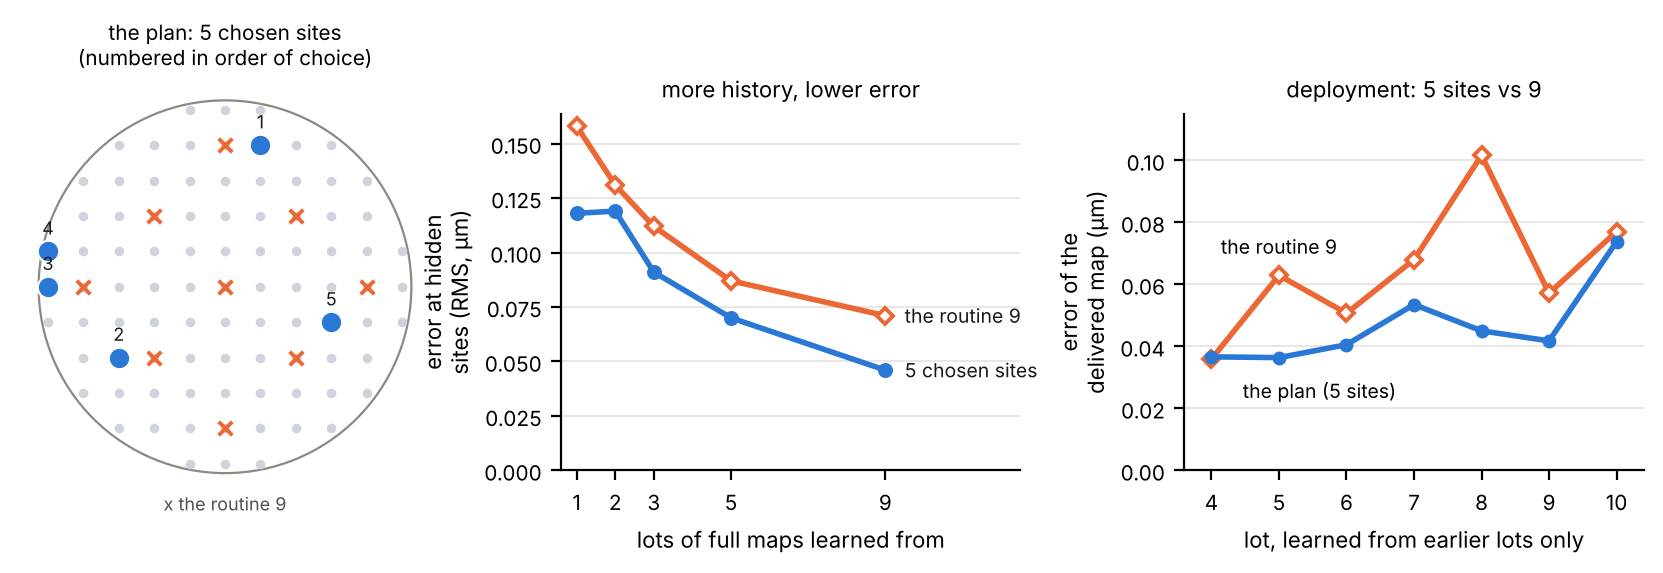

In [20]:
# Figure: the plan's sites, error against the number of reference lots, and the deployment lot by lot
fig = plt.figure(figsize=(8.2, 2.7))
ax0 = fig.add_axes([0.0, 0.12, 0.25, 0.78])
ax0.add_patch(plt.Circle((0, 0), 100, fill=False, color='#8a8984', lw=0.8))
ax0.scatter(xy[:, 0], xy[:, 1], s=6, color='#cfd4dc')
ax0.scatter(xy[routine, 0], xy[routine, 1], marker='x', s=24, color='#eb6834', lw=1.4)
plan_sites = FINAL['sites'][:FINAL['k']]
ax0.scatter(xy[plan_sites, 0], xy[plan_sites, 1], s=60, color='#2a78d6', edgecolor='white', lw=0.8, zorder=3)
for i, s_ in enumerate(plan_sites):
    ax0.text(xy[s_, 0], xy[s_, 1] + 9, str(i + 1), fontsize=6.5, ha='center', color='#1a1a1a')
ax0.set_aspect('equal'); ax0.axis('off')
ax0.set_title('the plan: 5 chosen sites\n(numbered in order of choice)', fontsize=7.5)
ax0.text(0, -120, 'x the routine 9', fontsize=6.5, ha='center', color='#52514e')

ax1 = fig.add_axes([0.33, 0.17, 0.28, 0.66])
lt = T_ref[T_ref.kind == 'lots']
for name, col, mk, lab in [('chosen 5', '#2a78d6', 'o', '5 chosen sites'), ('routine 9', '#eb6834', 'D', 'the routine 9')]:
    d = lt[lt.layout == name].sort_values('size')
    ax1.plot(d['size'], d.error, '-' + mk, color=col, lw=2, ms=4, mfc=col if mk == 'o' else 'white', mew=1.4)
    ax1.text(9.5, d.error.iloc[-1], lab, fontsize=7, va='center', color='#1a1a1a')
ax1.set_xticks([1, 2, 3, 5, 9])
ax1.set_xlim(0.6, 12.5)
ax1.set_ylim(0, None)
ax1.set_xlabel('lots of full maps learned from', fontsize=8)
ax1.set_ylabel('error at hidden\nsites (RMS, µm)', fontsize=8)
ax1.set_title('more history, lower error', fontsize=8)
ax1.grid(axis='y', color='#e4e3df', lw=0.6)
ax1.spines[['top', 'right']].set_visible(False)
ax1.tick_params(labelsize=7.5)

ax2 = fig.add_axes([0.71, 0.17, 0.28, 0.66])
per = pd.DataFrame({L: summary(FWD, [L]) for L in later}).T
ax2.plot(later, per.routine9_map, '-D', color='#eb6834', lw=2, ms=4, mfc='white', mew=1.4)
ax2.plot(later, per.map_error, '-o', color='#2a78d6', lw=2, ms=4)
ax2.text(5, per.routine9_map[5] + 0.007, 'the routine 9', fontsize=7, ha='center')
ax2.text(5.6, per.map_error[5] - 0.013, 'the plan (5 sites)', fontsize=7, ha='center')
ax2.set_xticks(later)
ax2.set_xlim(3.6, 10.4)
ax2.set_ylim(0, 0.115)
ax2.set_xlabel('lot, learned from earlier lots only', fontsize=8)
ax2.set_ylabel('error of the\ndelivered map (µm)', fontsize=8)
ax2.set_title('deployment: 5 sites vs 9', fontsize=8)
ax2.grid(axis='y', color='#e4e3df', lw=0.6)
ax2.spines[['top', 'right']].set_visible(False)
ax2.tick_params(labelsize=7.5)
fig.savefig(os.path.join(FIG_DIR, 'part4_plan.png'), dpi=220, bbox_inches='tight')
plt.show()

**The measurement plan.** Learn the model from full maps spread over at least 3 lots, and keep adding
them: every lot lowers the error. Measure each wafer at 5 sites chosen by the model, mostly at the edge.
Re-measure a reading the check questions. If the flag fires, measure the full map. Otherwise predict
the map with its 90% ranges. Learned only from earlier lots, this gives the full 89-site map to
0.045 µm from 5 sites, against 0.067 µm from the routine 9, with ranges that hold 92% of the time.

## 10. Summary of part 4
- **Sites:** 4 chosen sites match the routine 9 and 5 beat it in all 10 lots, on the sites both leave
  unmeasured. The plan measures 5: the rule on training lots, with a floor of one site per shape so the
  flag can see a wafer like lot 1's.
- **Deployment:** learned from earlier lots only, the plan is within 10% of leave-one-lot-out (×1.10),
  inside the 1.25× pass rule. Map error 0.045 µm from 5 sites against 0.067 µm from the routine 9,
  better in 6 of 7 lots and tied on the seventh.
- **Staleness:** a plan frozen after lots 1 to 3 is 13% worse and loses one lot of seven to the
  routine 9; it degrades gradually.
- **Full maps:** error falls with every lot of history up to the 9 available; ranges need at least 2
  lots; full maps spread over lots beat the same number from one lot.
- **Cost:** about 5 sites per wafer on usual lots; an unusual lot sent for full maps costs more than the
  routine 9 while it lasts. The reference maps pay for themselves after about 22 wafers per full map,
  against the routine 9 without history.